Looking for an EEG stream...
Found it!
Start acquiring data


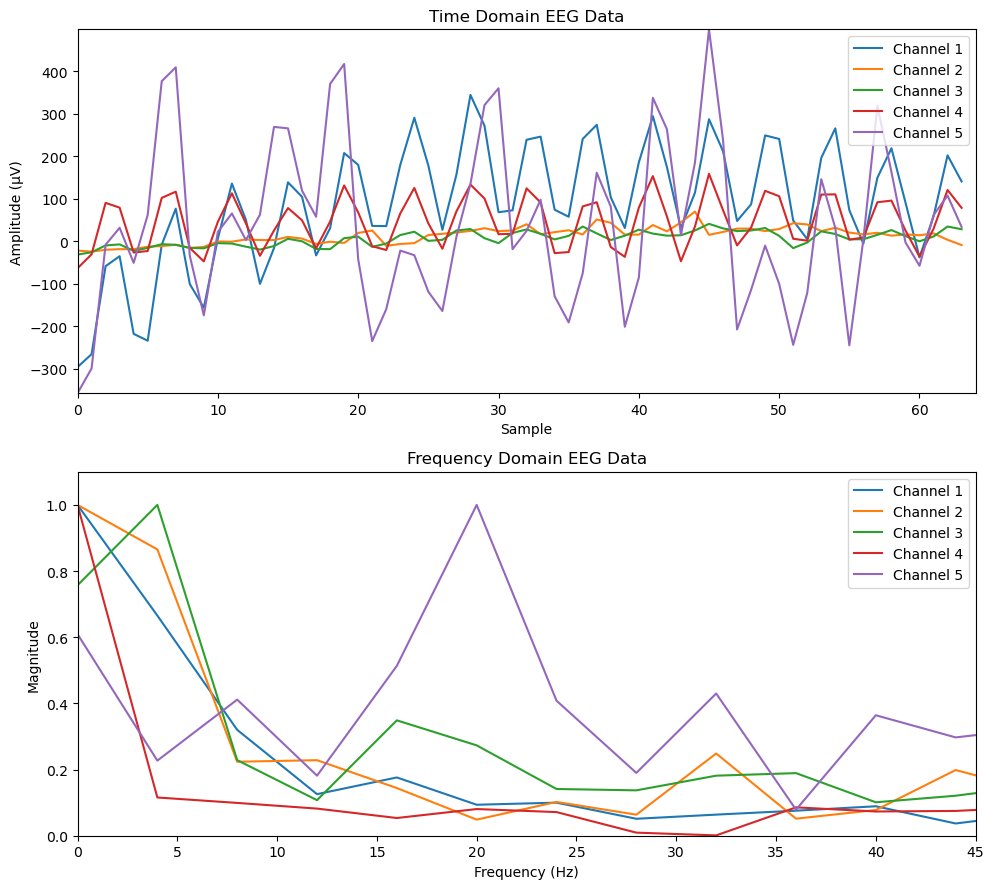

<Figure size 640x480 with 0 Axes>

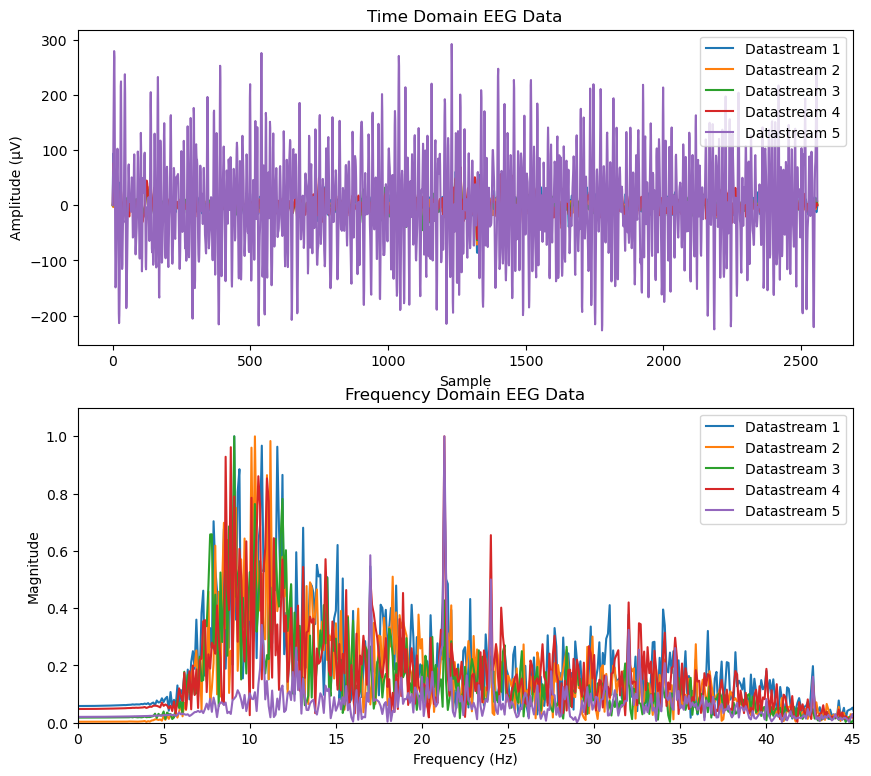

In [4]:
if __name__ == '__main__':
    record_live(input("Enter label for the recording: "))

In [2]:
import time
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.signal import butter, filtfilt
# Import functions from the utils module
from pylsl import StreamInlet, resolve_byprop

In [3]:
# Low SHIFT_LENGTH value because higher frequency EEG data is being recorded
SHIFT_LENGTH = 0.25

# Time to record and respond to the neural signal
RUNTIME_SECONDS = 10

def bandpass(data, fs, low= 8, high= 30, order=4):
    nyq = 0.5 * fs
    b, a = butter(order, [low/nyq, high/nyq], btype='band')

    # Apply the filter to the data using filtfilt for zero-phase filtering
    return filtfilt(b, a, data, axis=0)

"""
Attempt to connect to the Muse EEG device and throw an error if not found

Return: The StreamInlet that provides live EEG data
"""
def connect_eeg():

    # Search for active LSL streams and connect to Muse
    print('Looking for an EEG stream...')
    streams = resolve_byprop('type', 'EEG', timeout=2)
    if len(streams) == 0:
        raise RuntimeError('Can\'t find EEG stream.')
    else:
        print('Found it!')

    # Set active EEG stream to inlet and apply time correction
    print("Start acquiring data")
    inlet = StreamInlet(streams[0], max_chunklen=256)

    return inlet

def record_live(label):

    # Receive data stream from Muse
    inlet = connect_eeg()

    # Get the stream info
    fs = int(inlet.info().nominal_srate())

    # Initialize arrays to hold EEG data and timestamps
    collective_eeg_data = np.empty((0, 5))
    collective_eeg_time = np.empty(0)

    # Set up interactive plotting
    plt.ion()
    fig, (ax_time, ax_freq) = plt.subplots(2, 1, figsize=(10, 9))

    # Initialize variables for time and frequency domain plots
    time_lines = [ax_time.plot([], [])[0] for _ in range(5)]
    freq_lines = [ax_freq.plot([], [])[0] for _ in range(5)]

    # Set axis limits and labels
    ax_time.set_title("Time Domain EEG Data")
    ax_time.set_xlabel("Sample")
    ax_time.set_ylabel("Amplitude (µV)")
    ax_freq.set_title("Frequency Domain EEG Data")
    ax_freq.set_xlabel("Frequency (Hz)")
    ax_freq.set_ylabel("Magnitude")

    # Add line labels
    for i, line in enumerate(time_lines):
        line.set_label(f"Channel {i+1}")
    for i, line in enumerate(freq_lines):
        line.set_label(f"Channel {i+1}")

    # Add legends
    ax_time.legend(loc='upper right')
    ax_freq.legend(loc='upper right')

    plt.tight_layout()

    samples_collected = 0
    target_samples = int(RUNTIME_SECONDS * fs)

    while samples_collected < target_samples:
        eeg_data, timestamp = inlet.pull_chunk(
            timeout=1, max_samples=int(SHIFT_LENGTH * fs))
        np_eeg_data = np.asarray(eeg_data)
        np_eeg_time = np.asarray(timestamp)

        if (np_eeg_data.shape[0] != 0):        
            samples_collected += np_eeg_data.shape[0]

            collective_eeg_data = np.append(collective_eeg_data, np_eeg_data, axis = 0)
            collective_eeg_time = np.append(collective_eeg_time, np_eeg_time, axis=0)

            freq_arr_2d, mag_arr_2d = multidimensional_tTf(collective_eeg_data, fs)

            interactive_plot(ax_time, ax_freq, time_lines, freq_lines, collective_eeg_data, freq_arr_2d, mag_arr_2d)
            
        now_time = time.time()


    # Save final figure
    plt.ioff()
    plt.savefig(f"{int(now_time)}_{label}_time_&_freq_domain.png")
    plt.show()

    # Create filtered EEG data and frequency domain representations
    filtered_eeg_data = filter_data(collective_eeg_data, fs)
    freq_arr_2d, mag_arr_2d = multidimensional_tTf(filtered_eeg_data, fs)

    plot_time_and_freq(freq_arr_2d, mag_arr_2d, filtered_eeg_data, now_time, label)

    export_data_csv(filtered_eeg_data, collective_eeg_time, now_time, label)
    export_segmented_csv(filtered_eeg_data, now_time, fs, label)

def interactive_plot(ax_time, ax_freq, time_lines, freq_lines, time_arr, freq_arr_2d, mag_arr_2d):
    # Update time domain lines
    for i, line in enumerate(time_lines):
        line.set_data(np.arange(time_arr.shape[0]), time_arr[:, i])
        ax_time.set_xlim(0, time_arr.shape[0])
        ax_time.set_ylim(np.min(time_arr), np.max(time_arr))

    # Update frequency domain lines
    for i, line in enumerate(freq_lines):
        line.set_data(freq_arr_2d[i], mag_arr_2d[i])
        ax_freq.set_xlim(0, 45)
        ax_freq.set_ylim(0, 1.1)

    # Redraw
    plt.pause(0.01)

def plot_time_and_freq(freqs, mag, data, now_time, label):
    plt.figure(figsize=(10, 9))
    plt.tight_layout()
    
    # First subplot (top)
    plt.subplot(2, 1, 1)
    labels = [f"Datastream {i+1}" for i in range(data.shape[1])]
    plt.plot(data, label = labels)
    plt.title("Time Domain EEG Data")
    plt.xlabel("Sample")
    plt.ylabel("Amplitude (µV)")
    plt.legend(loc = 'upper right')

    plt.subplot(2, 1, 2)
    plt.plot(freqs.T, mag.T, label = labels)
    plt.title("Frequency Domain EEG Data")
    plt.xlabel("Frequency (Hz)")
    plt.xlim(0, 45)
    plt.ylabel("Magnitude")
    plt.ylim(0, 1.1)
    plt.legend(loc = 'upper right')
    plt.savefig(f"{int(now_time)}_FILTERED_{label}_time_&_freq_domain.png")

def export_data_csv(collective_eeg_data, collective_eeg_time, now_time, label):
    df_time = pd.DataFrame({'timestamp': collective_eeg_time, 'ch_1_eeg_value': collective_eeg_data[:, 0], 'ch_2_eeg_value': collective_eeg_data[:, 1], 'ch_3_eeg_value': collective_eeg_data[:, 2], 'ch_4_eeg_value': collective_eeg_data[:, 3], 'ch_5_eeg_value': collective_eeg_data[:, 4]})
    df_time.to_csv(f'{int(now_time)}_{label}_time_data_with_timestamps.csv', index=False)

def segment_data(collective_eeg_data, fs, label, n_samples, window_size = 2):
    window_samples = int(window_size * fs)

    segments = []
    
    for start in range(0, n_samples - window_samples + 1, window_samples):
        segment = collective_eeg_data[start:start+window_samples, :]  # shape: (window_samples, num_channels)
        segment_flat = segment.T.flatten()  # shape: (channels * window_samples)
        segments.append(np.append(segment_flat, label))

    return segments, window_samples

def export_segmented_csv(collective_eeg_data, now_time, fs, label):
    n_samples, n_channels = collective_eeg_data.shape
    segments, window_samples = segment_data(collective_eeg_data, fs, label, n_samples, window_size = 2)
    
    # Create column names
    col_names = [f"ch{ch+1}_samp{i}" for ch in range(n_channels) for i in range(window_samples)] + [label]

    df = pd.DataFrame(segments, columns=col_names)

    # Save to CSV
    df.to_csv(f'{int(now_time)}_{label}_segmented_data.csv', index=False)

def multidimensional_tTf(collective_eeg_data, fs):
    num_signals, signal_length = collective_eeg_data.T.shape
    fft_length = signal_length // 2 + 1
    
    freq_arr_2d = np.zeros((num_signals, fft_length))
    mag_arr_2d = np.zeros((num_signals, fft_length))
    transposed_collective_eeg_data = collective_eeg_data.T
    for i in range(transposed_collective_eeg_data.shape[0]):
        f, m = time_to_frequency_domain(transposed_collective_eeg_data[i], fs)
        freq_arr_2d[i] = f
        mag_arr_2d[i] = m

    return freq_arr_2d, mag_arr_2d

def filter_data(np_eeg_data, fs):
    transposed_data = np_eeg_data.T
    tr_bandpassed_data = np.empty_like(transposed_data)
    for i in range(transposed_data.shape[0]):
        tr_bandpassed_data[i] = bandpass(transposed_data[i], fs, low=8, high=40, order=4)
    bandpassed_data = tr_bandpassed_data.T

    return bandpassed_data

def time_to_frequency_domain(signal, fs):
    n = len(signal)
    magnitude = np.abs(np.fft.rfft(signal)) / n
    normalized_magnitude = magnitude / np.max(magnitude)
    freqs = np.fft.rfftfreq(n, 1/fs)

    return freqs, normalized_magnitude